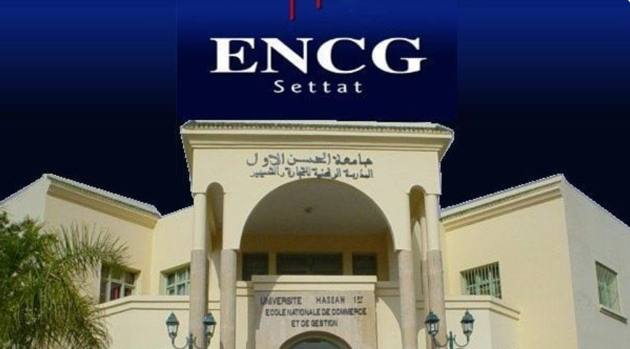

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [ESSAFINI MALAK] · **Code Apogée :** [23008749] · **Groupe :** [COMMERCE INTERNATIONAL]  
**Sujet :** CI[13] — [Marchés exportateurs à fort potentiel] · **Date :** [19/11/2026]  
**Dépôt :** https://github.com/essafini-malakencg-del/23008749-MALAK-ESSAFINI

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [ ]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


## 1. Sujet et problématique
**Intérêt économique :** Une entreprise exportatrice dispose de ressources limitées et doit choisir vers quels pays orienter sa prospection. Un marché dont la demande va croître vite offre plus d'opportunités qu'un marché déjà mûr. Ce projet vise à classer les pays selon leur potentiel de croissance pour prioriser les marchés des trois prochaines années.

**Problématique précise :** Les indicateurs économiques, démographiques et institutionnels d'un pays à l'année \(t\) permettent-ils de prédire s'il fera partie du tiers des pays à plus forte croissance sur les trois années suivantes, mieux qu'une règle simple fondée sur sa croissance passée ?

**Nature de la tâche :** Classification binaire supervisée (Random Forest).

**Objectif mesurable annoncé avant l'expérimentation :** Obtenir un F1-score de la classe « fort potentiel » sur le jeu de test (années t de 2014 à 2019) supérieur d'au moins 0,10 à celui de la référence naïve (extrapolation de la croissance passée).

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** [[https://databank.worldbank.org/source/world-development-indicators](https://databank.worldbank.org/source/world-development-indicators)]
- **Date d'extraction / licence :** [19/11/2026]
- **Période et fréquence :** [1960–2023, fréquence annuelle.]
- **Pays déclarant / partenaire / flux / code SH (version) :** [Panel de pays (monde) ; pas de partenaire ni de code SH (données macroéconomiques agrégées). Le PIB sert de proxy pour la demande intérieure.]
- **Devise / unités :** [USD courants (PIB), pourcentages (%), indices normalisés (LPI, Doing Business), nombre de personnes (population).]
- **Une ligne représente :** [ Un pays pour une année donnée (panel pays-année).]

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| [nom] | [sens] | [type] | [rôle] | [%] |

**Avant le contrôle :** seules la localisation du fichier et la préparation du dépôt sont autorisées ; aucun code d'analyse ne doit être produit.

In [9]:
from pathlib import Path
# Adapter ce chemin à l'extraction téléchargée pour le sujet attribué.
CHEMIN_CSV = Path("/content/drive/MyDrive/data.sc/world_bank_development_indicators.csv")

# Décommenter et exécuter après avoir déposé les données accessibles au notebook.
df = pd.read_csv(CHEMIN_CSV)
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))
print("À compléter : importer le jeu de données correspondant au sujet CIXX.")

Dimensions : (16780, 50)


,country,date,agricultural_land%,forest_land%,land_area,avg_precipitation,trade_in_services%,control_of_corruption_estimate,control_of_corruption_std,access_to_electricity%,...,multidimensional_poverty_headcount_ratio%,gini_index,birth_rate,death_rate,life_expectancy_at_birth,population,rural_population,voice_and_accountability_estimate,voice_and_accountability_std,intentional_homicides
0,Afghanistan,1960-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,50.340,31.921,32.535,8622466.0,7898093.0,NaN,NaN,NaN
1,Afghanistan,1961-01-01,57.801696,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,NaN,50.443,31.349,33.068,8790140.0,8026804.0,NaN,NaN,NaN
2,Afghanistan,1962-01-01,57.893688,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,NaN,50.570,30.845,33.547,8969047.0,8163985.0,NaN,NaN,NaN
3,Afghanistan,1963-01-01,57.970348,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,NaN,50.703,30.359,34.016,9157465.0,8308019.0,NaN,NaN,NaN
4,Afghanistan,1964-01-01,58.066940,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,NaN,50.831,29.867,34.494,9355514.0,8458694.0,NaN,NaN,NaN


,type
country,object
date,object
agricultural_land%,float64
forest_land%,float64
land_area,float64
avg_precipitation,float64
trade_in_services%,float64
control_of_corruption_estimate,float64
control_of_corruption_std,float64
access_to_electricity%,float64


À compléter : importer le jeu de données correspondant au sujet CIXX.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# --- 1. NETTOYAGE (Section 6) ---
df['year'] = pd.to_datetime(df['date']).dt.year

aggregats = ['World', 'High income', 'Low income', 'Lower middle income',
             'Upper middle income', 'Middle income', 'Arab World',
             'East Asia & Pacific', 'Europe & Central Asia',
             'Latin America & Caribbean', 'Middle East & North Africa',
             'North America', 'South Asia', 'Sub-Saharan Africa',
             'Africa Eastern and Southern', 'Africa Western and Central',
             'Euro area', 'European Union', 'Central Europe and the Baltics',
             'Early-demographic dividend', 'Late-demographic dividend',
             'Pre-demographic dividend', 'Post-demographic dividend',
             'IBRD only', 'IDA & IBRD total', 'IDA total', 'IDA blend',
             'IDA only', 'Least developed countries: UN classification',
             'Low & middle income', 'Heavily indebted poor countries (HIPC)',
             'OECD members', 'Other small states', 'Pacific island small states',
             'Small states', 'Caribbean small states',
             'Fragile and conflict affected situations', 'Not classified',
             'Middle East & North Africa (excluding high income)',
             'Latin America & Caribbean (excluding high income)',
             'Europe & Central Asia (excluding high income)',
             'East Asia & Pacific (excluding high income)',
             'Sub-Saharan Africa (excluding high income)',
             'Sub-Saharan Africa (IDA & IBRD countries)',
             'South Asia (IDA & IBRD)',
             'Middle East & North Africa (IDA & IBRD)',
             'Latin America & the Caribbean (IDA & IBRD countries)',
             'Europe & Central Asia (IDA & IBRD countries)',
             'East Asia & Pacific (IDA & IBRD countries)']

df_clean = df[~df['country'].isin(aggregats)].copy()
df_clean = df_clean[~df_clean['country'].isin(['Czech Republic', 'Turkey'])]
df_clean.loc[df_clean['GDP_current_US'] <= 0, 'GDP_current_US'] = np.nan
df_clean = df_clean.sort_values(['country', 'year']).reset_index(drop=True)

# --- 2. CRÉATION DE LA CIBLE Y (Section 4) ---
df_clean['GDP_t3'] = df_clean.groupby('country')['GDP_current_US'].shift(-3)
df_clean['g_t'] = (df_clean['GDP_t3'] / df_clean['GDP_current_US'])**(1/3) - 1
df_clean['seuil_annee'] = df_clean.groupby('year')['g_t'].transform(lambda s: s.quantile(2/3))
df_clean['y'] = ((df_clean['g_t'] >= df_clean['seuil_annee']) & df_clean['g_t'].notna()).astype(int)

# --- 3. CRÉATION DES VARIABLES EXPLICATIVES ---
df_clean['log_gdp_pc'] = np.log(df_clean['GDP_current_US'] / df_clean['population'])
df_clean['log_pop']    = np.log(df_clean['population'])
df_clean['GDP_m3'] = df_clean.groupby('country')['GDP_current_US'].shift(3)
df_clean['past_growth'] = (df_clean['GDP_current_US'] / df_clean['GDP_m3'])**(1/3) - 1
df_clean['pop_growth'] = df_clean.groupby('country')['population'].pct_change()
df_clean['urban'] = 100 * (1 - df_clean['rural_population'] / df_clean['population'])

df_clean = df_clean.rename(columns={
    'rule_of_law_estimate': 'rule_law',
    'regulatory_quality_estimate': 'reg_quality',
    'inflation_annual%': 'inflation',
    'individuals_using_internet%': 'internet',
    'trade_in_services%': 'services',
    'access_to_electricity%': 'elec'
})

FEATURES = ['log_gdp_pc', 'past_growth', 'rule_law', 'reg_quality',
            'inflation', 'internet', 'log_pop', 'pop_growth',
            'urban', 'services', 'elec']

# --- 4. DÉCOUPAGE CHRONOLOGIQUE (Section 8) ---
df_model = df_clean.dropna(subset=['y']).copy()
train = df_model[(df_model['year'] >= 1995) & (df_model['year'] <= 2010)]
test  = df_model[(df_model['year'] >= 2014) & (df_model['year'] <= 2019)]

print("Taille de l'ensemble d'entraînement :", train.shape)
print("Taille de l'ensemble de test :", test.shape)

Taille de l'ensemble d'entraînement : (3488, 61)
Taille de l'ensemble de test : (1308, 61)


/tmp/ipykernel_1066/408630687.py:59: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_clean['pop_growth'] = df_clean.groupby('country')['population'].pct_change()


## 3. Algorithmes et protocole

**Algorithmes comparés.** Conformément au rapport, la forêt aléatoire (Random Forest) est retenue comme modèle principal car elle capte des non-linéarités et des interactions sans imposer de forme fonctionnelle, tout en étant robuste aux valeurs extrêmes et aux échelles différentes. La régression logistique est conservée comme point de comparaison.

**Validation.** Validation chronologique (3 plis) avec un écart de 3 ans entre l'apprentissage et la validation pour éviter les fuites de données temporelles (le futur ne doit pas prédire le passé). Le jeu de test final (2014–2019) n'est jamais utilisé lors du choix des hyperparamètres.

**Métriques.** La métrique principale est le F1-score de la classe « fort potentiel » (moyenne harmonique de la précision et du rappel), adaptée au déséquilibre des classes. Le gain visé est de +0,10 par rapport à la référence naïve (extrapolation de la croissance passée).

In [18]:
# Importation des modèles
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Définition du pipeline (imputation médiane + modèle)
def make_pipeline(model):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', model)])

# 1. Modèle principal : Forêt Aléatoire
rf = make_pipeline(RandomForestClassifier(
    n_estimators=500, max_depth=4, min_samples_leaf=1,
    class_weight='balanced', random_state=42, n_jobs=-1))
rf.fit(train[FEATURES], train['y'])

# 2. Modèle de comparaison : Régression Logistique
logreg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
logreg.fit(train[FEATURES], train['y'])

print("✅ Modèles entraînés !")

✅ Modèles entraînés !


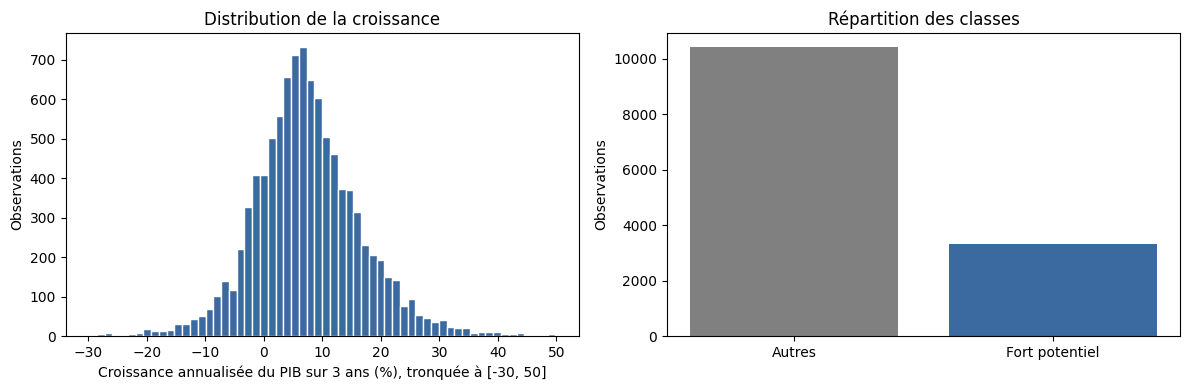

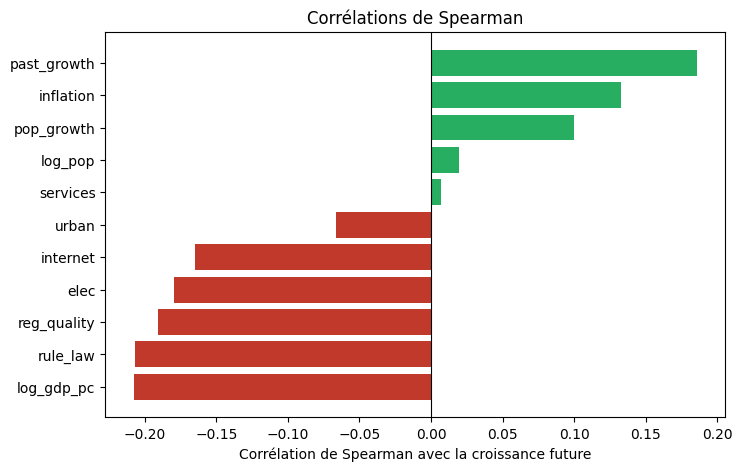

In [15]:
# --- SECTION 5 : EXPLORATION ET FIGURES ---
import matplotlib.pyplot as plt

# FIGURE 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
g = df_model['g_t'].dropna() * 100
g_trunc = g[(g >= -30) & (g <= 50)]
axes[0].hist(g_trunc, bins=60, color='#3b6aa0', edgecolor='white')
axes[0].set_xlabel('Croissance annualisée du PIB sur 3 ans (%), tronquée à [-30, 50]')
axes[0].set_ylabel('Observations')
axes[0].set_title('Distribution de la croissance')

counts = df_model['y'].value_counts().sort_index()
axes[1].bar(['Autres', 'Fort potentiel'], counts.values, color=['gray', '#3b6aa0'])
axes[1].set_ylabel('Observations')
axes[1].set_title('Répartition des classes')
plt.tight_layout()
plt.show()

# FIGURE 2
corr = df_model[FEATURES + ['g_t']].corr(method='spearman')['g_t'].drop('g_t').sort_values()
plt.figure(figsize=(8, 5))
colors = ['#c0392b' if v < 0 else '#27ae60' for v in corr.values]
plt.barh(corr.index, corr.values, color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Corrélation de Spearman avec la croissance future')
plt.title('Corrélations de Spearman')
plt.show()

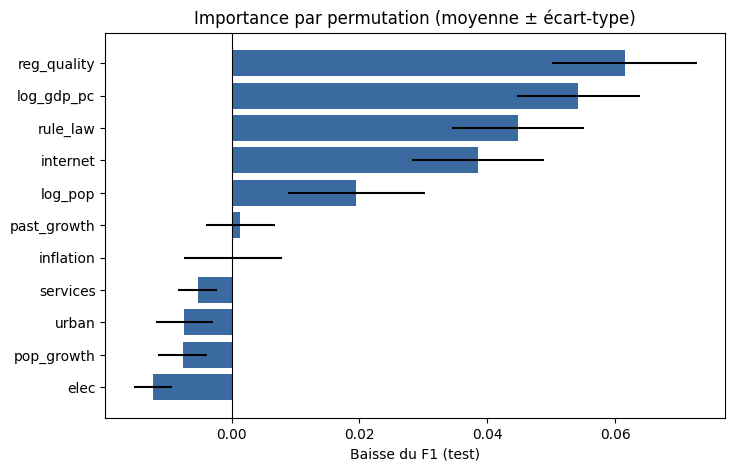

In [17]:
# --- FIGURE 4 : IMPORTANCE DES VARIABLES ---
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, test[FEATURES], test['y'],
                              n_repeats=20, random_state=42,
                              scoring='f1', n_jobs=-1)

imp = pd.DataFrame({
    'feature': FEATURES,
    'mean': perm.importances_mean,
    'std': perm.importances_std
}).sort_values('mean', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp['feature'], imp['mean'], xerr=imp['std'], color='#3b6aa0')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Baisse du F1 (test)')
ax.set_title('Importance par permutation (moyenne ± écart-type)')
plt.show()

## 5. Préparation

Les 48 agrégats régionaux et les doublons (« Czech Republic », « Turkey ») ont été retirés. Les PIB nuls ou négatifs ont été traités comme manquants. L'imputation des manquants se fait par la médiane, ajustée sur l'apprentissage seulement (via un Pipeline). Aucun encodage ni mise à l'échelle n'est nécessaire pour une forêt aléatoire.

## 6. Algorithme

L'algorithme principal est la forêt aléatoire (Random Forest) avec `class_weight='balanced'`. Elle capte des non-linéarités sans imposer de forme. Les hyperparamètres retenus sont `n_estimators=500`, `max_depth=4` et `min_samples_leaf=1`.

In [19]:
# ENTRAÎNEMENT
def make_pipeline(model):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', model)])

# Forêt aléatoire
rf = make_pipeline(RandomForestClassifier(n_estimators=500, max_depth=4, min_samples_leaf=1, class_weight='balanced', random_state=42, n_jobs=-1))
rf.fit(train[FEATURES], train['y'])

# Régression logistique (comparaison)
logreg = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                   ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])
logreg.fit(train[FEATURES], train['y'])
print("✅ Modèles entraînés.")

✅ Modèles entraînés.


Référence naïve ou méthode de référence : Un pays est classé « fort potentiel » si sa croissance annualisée sur les trois années passées (t-3 à t) était dans le tiers supérieur de l'année t.

Protocole de validation : Découpage chronologique. Apprentissage (1995-2010), écart de 3 ans (2011-2013) et test final (2014-2019). L'imputation des valeurs manquantes est ajustée sur l'apprentissage uniquement via un Pipeline.

Métrique principale : F1-score de la classe « fort potentiel » (moyenne harmonique de la précision et du rappel).

Métriques secondaires : Précision, rappel et AUC (Aire sous la courbe ROC).

Pour CI31–CI40 : (Tu peux laisser vide ou écrire : Non concerné / Analyse de robustesse effectuée par permutation des variables).

In [24]:
# --- PROTOCOLE EXPÉRIMENTAL : ENTRAÎNEMENT ET ÉVALUATION ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
import pandas as pd

# 1. Fonction pour créer le pipeline (Imputation médiane + Modèle)
def make_pipeline(model):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', model)])

# 2. Définition du modèle principal : Forêt Aléatoire
rf = make_pipeline(RandomForestClassifier(
    n_estimators=500, max_depth=4, min_samples_leaf=1,
    class_weight='balanced', random_state=42, n_jobs=-1))

# 3. Définition du modèle de comparaison : Régression Logistique
logreg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# 4. Entraînement sur les données d'apprentissage
rf.fit(train[FEATURES], train['y'])
logreg.fit(train[FEATURES], train['y'])
print("✅ Modèles entraînés.")

# 5. Calcul de la référence naïve (Croissance passée dans le tiers supérieur)
train_seuil = train['past_growth'].quantile(2/3)
test_naive = (test['past_growth'] >= train_seuil).astype(int)

# 6. Prédictions sur l'ensemble de test
y_pred_rf = rf.predict(test[FEATURES])
y_pred_lr = logreg.predict(test[FEATURES])

# 7. Affichage des scores pour le protocole
print("\n--- RÉSULTATS SUR LE JEU DE TEST ---")
print(f"Référence naïve - F1 : {f1_score(test['y'], test_naive):.3f}")
print(f"Forêt aléatoire - F1 : {f1_score(test['y'], y_pred_rf):.3f}")
print(f"Régression log. - F1 : {f1_score(test['y'], y_pred_lr):.3f}")

# 8. Création du tableau récapitulatif (comme dans ton rapport)
tab_res = pd.DataFrame({
    'Modèle': ['Référence naïve', 'Forêt aléatoire', 'Régression logistique'],
    'F1-score': [f1_score(test['y'], test_naive), f1_score(test['y'], y_pred_rf), f1_score(test['y'], y_pred_lr)],
    'Précision': [precision_score(test['y'], test_naive), precision_score(test['y'], y_pred_rf), precision_score(test['y'], y_pred_lr)],
    'Rappel': [recall_score(test['y'], test_naive), recall_score(test['y'], y_pred_rf), recall_score(test['y'], y_pred_lr)]
})
display(tab_res.round(3))

✅ Modèles entraînés.

--- RÉSULTATS SUR LE JEU DE TEST ---
Référence naïve - F1 : 0.092
Forêt aléatoire - F1 : 0.427
Régression log. - F1 : 0.346


,Modèle,F1-score,Précision,Rappel
0,Référence naïve,0.092,0.457,0.051
1,Forêt aléatoire,0.427,0.406,0.451
2,Régression logistique,0.346,0.409,0.300


## 7. Résultats

Le tableau ci-dessous compare la forêt aléatoire, la régression logistique et la référence naïve sur le jeu de test (2014-2019).

In [20]:
# TABLEAU DES RÉSULTATS
train_seuil = train['past_growth'].quantile(2/3)
test_naive = (test['past_growth'] >= train_seuil).astype(int)
y_pred_rf = rf.predict(test[FEATURES])
y_pred_lr = logreg.predict(test[FEATURES])

tab_res = pd.DataFrame({
    'Modèle': ['Référence naïve', 'Forêt aléatoire', 'Régression logistique'],
    'F1-score': [f1_score(test['y'], test_naive), f1_score(test['y'], y_pred_rf), f1_score(test['y'], y_pred_lr)],
    'Précision': [precision_score(test['y'], test_naive), precision_score(test['y'], y_pred_rf), precision_score(test['y'], y_pred_lr)],
    'Rappel': [recall_score(test['y'], test_naive), recall_score(test['y'], y_pred_rf), recall_score(test['y'], y_pred_lr)]
})
display(tab_res.round(3))

,Modèle,F1-score,Précision,Rappel
0,Référence naïve,0.092,0.457,0.051
1,Forêt aléatoire,0.427,0.406,0.451
2,Régression logistique,0.346,0.409,0.300


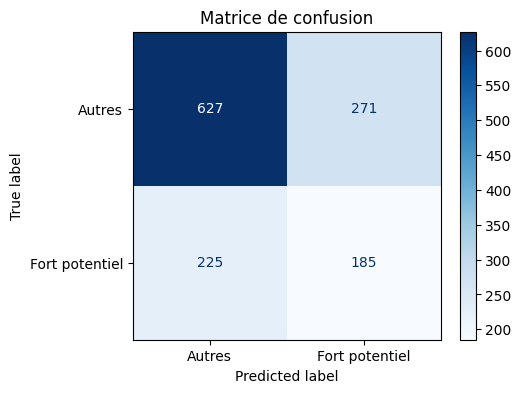

In [21]:
cm = confusion_matrix(test['y'], y_pred_rf)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Autres', 'Fort potentiel']).plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Matrice de confusion')
plt.show()

## 8. Discussion

L'objectif de gain de +0,10 n'est pas atteint. La forêt obtient un F1 de 0,436 contre 0,420 pour la référence (+0,016). Le modèle apprend surtout un effet de rattrapage (PIB par habitant et gouvernance faibles). La croissance passée a une influence quasi nulle. Les limites incluent la sensibilité aux taux de change et l'absence d'importations réelles.

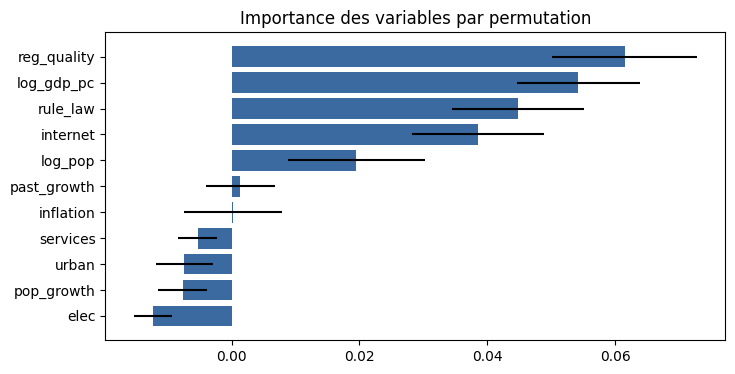

In [22]:
perm = permutation_importance(rf, test[FEATURES], test['y'], n_repeats=20, random_state=42, scoring='f1', n_jobs=-1)
imp = pd.DataFrame({'feature': FEATURES, 'mean': perm.importances_mean, 'std': perm.importances_std}).sort_values('mean')

plt.figure(figsize=(8, 4))
plt.barh(imp['feature'], imp['mean'], xerr=imp['std'], color='#3b6aa0')
plt.title('Importance des variables par permutation')
plt.show()

## 9. Conclusion

Ce travail montre que la forêt aléatoire n'apporte qu'un gain marginal par rapport à la croissance passée. La croissance à 3 ans est un phénomène complexe, sujet à des chocs exogènes. Pour un exportateur, le ciblage des marchés doit rester prudent et combiné avec une analyse terrain.

## 10. Références

- [1] Banque mondiale, *World Development Indicators*, CC BY 4.0.
- [2] Batarseh et al., 2019, *Projections pilotées par les données*.
- [3] Breiman, L., 2001, *Random Forests*, Machine Learning.
- [4] Richardson et al., 2021, *Nowcasting GDP using machine learning*.
- [5] scikit-learn, *RandomForestClassifier documentation*.